# Assessing the Impact of Market Shifts on Automotive Efficiency (1975-2025)
Run the setup cells first (imports, data, aggregation), then run each plot cell on its own.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)


In [2]:
# Load the dataset
vehicles = pd.read_csv(
    "https://www.fueleconomy.gov/feg/epadata/vehicles.csv", low_memory=False
)

# DATA CLEANING & RE-CATEGORIZATION
cols = ["make", "model", "year", "VClass", "cylinders", "displ", "drive",
        "trany", "comb08", "highway08", "city08", "fuelType1"]
df = vehicles[cols].copy()

# Remove rows with missing critical values
df = df.dropna(subset=["year", "comb08", "displ", "trany"])

vclass = df["VClass"].fillna("")
trany = df["trany"].fillna("")

df["vehicle_class"] = np.select(
    [
        vclass.str.contains(r"SUV|Sport Utility", case=False, regex=True),
        vclass.str.contains(r"Wagon|Sedan|Passenger Car", case=False, regex=True),
        vclass.str.contains(r"Truck|Pickup", case=False, regex=True),
    ],
    ["SUV", "Car", "Truck"],
    default="Other",
)

df["drivetrain"] = np.select(
    [
        trany.str.contains("Auto", case=False, regex=False),
        trany.str.contains("Manual", case=False, regex=False),
    ],
    ["Automatic", "Manual"],
    default="Other",
)

# Keep only the primary classes for the analysis
df = df[df["vehicle_class"].isin(["SUV", "Car", "Truck"])
        & df["drivetrain"].isin(["Automatic", "Manual"])].copy()


In [3]:
# AGGREGATION FOR TREND LINES
trend = (
    df.groupby(["year", "vehicle_class"], as_index=False)
      .agg(avg_mpg=("comb08", "mean"), avg_displ=("displ", "mean"), n=("comb08", "size"))
)
avg_all = df.groupby("year", as_index=False).agg(avg_mpg_all=("comb08", "mean"))

# ORGANIZE PLOTTING ORDER (classes sorted by mean of yearly average MPG, descending)
class_order = (
    trend.groupby("vehicle_class")["avg_mpg"].mean()
         .sort_values(ascending=False).index.tolist()
)
trend["vehicle_class"] = pd.Categorical(trend["vehicle_class"], categories=class_order)
df["vehicle_class"] = pd.Categorical(df["vehicle_class"], categories=class_order)


## Plot 1: MPG Distribution by Class

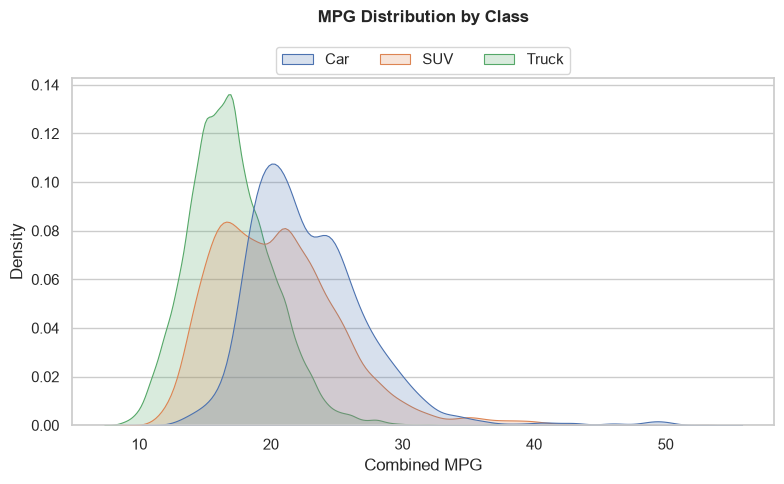

In [4]:
# Plot 1: Density plot of MPG
fig1, ax1 = plt.subplots(figsize=(8, 5))
sns.kdeplot(
    data=df, x="comb08", hue="vehicle_class", hue_order=class_order,
    fill=True, alpha=0.22, linewidth=0.8, common_norm=False, ax=ax1,
)
ax1.set(xlabel="Combined MPG", ylabel="Density")
ax1.set_title("MPG Distribution by Class", pad=40, fontweight="bold")
ax1.grid(False, axis="x")
sns.move_legend(ax1, "lower center", bbox_to_anchor=(0.5, 0.99), ncol=len(class_order), title=None)
fig1.tight_layout()
plt.show()


## Plot 2: Vehicle Shifts by Classes

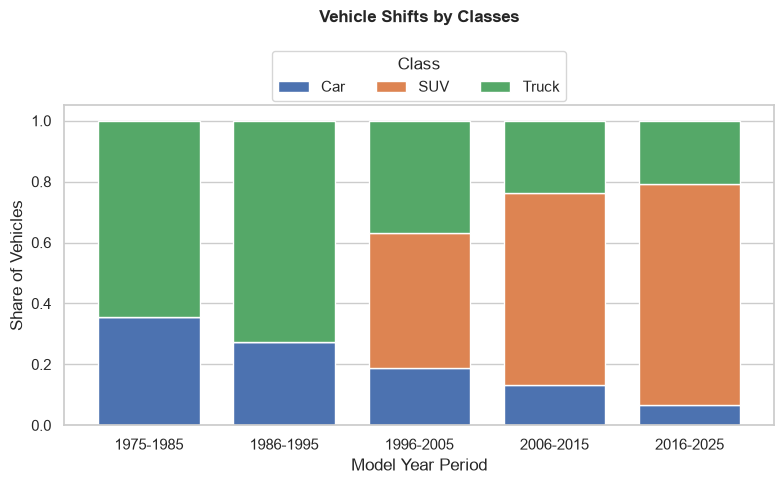

In [5]:
# Plot 2: Stacked share of vehicles by class and model-year period
df_year = df.copy()
df_year["period"] = pd.cut(
    df_year["year"],
    bins=[1974, 1985, 1995, 2005, 2015, 2026],
    labels=["1975-1985", "1986-1995", "1996-2005", "2006-2015", "2016-2025"],
    include_lowest=True,
    right=True,
)

count_tbl = (
    df_year.groupby(["period", "vehicle_class"], observed=True)
           .size().rename("n").reset_index()
)
count_tbl["share"] = count_tbl["n"] / count_tbl.groupby("period", observed=True)["n"].transform("sum")

share_wide = (
    count_tbl.pivot(index="period", columns="vehicle_class", values="share")
             .reindex(columns=class_order).fillna(0)
)

fig2, ax2 = plt.subplots(figsize=(8, 5))
share_wide.plot(kind="bar", stacked=True, width=0.75, ax=ax2)
ax2.set(xlabel="Model Year Period", ylabel="Share of Vehicles")
ax2.set_title("Vehicle Shifts by Classes", pad=60, fontweight="bold")
ax2.tick_params(axis="x", rotation=0)
ax2.grid(False, axis="x")
ax2.legend(title="Class", loc="lower center", bbox_to_anchor=(0.5, 0.99), ncol=len(class_order))
fig2.tight_layout()
plt.show()


## Plot 3: Displacement vs. MPG

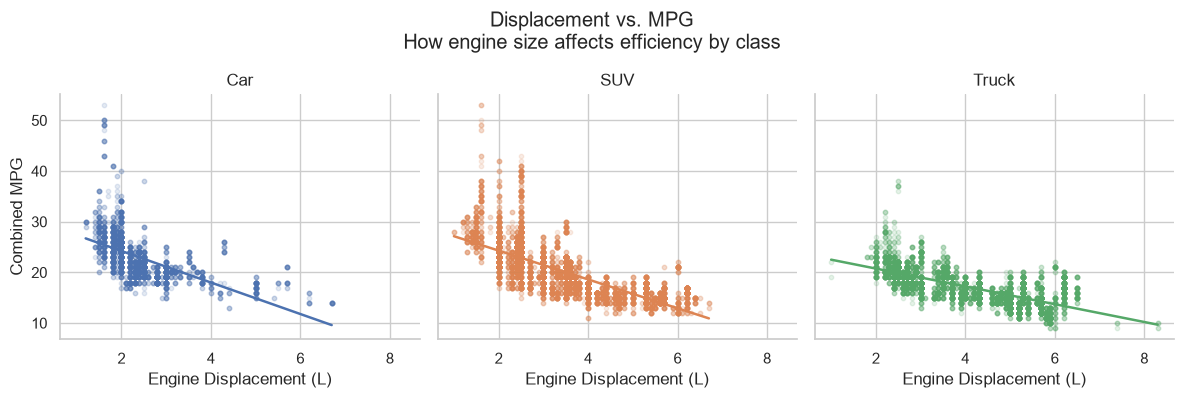

In [6]:
# Plot 3: The Efficiency Trade-off (scatter + linear fit, faceted by class)
g = sns.lmplot(
    data=df, x="displ", y="comb08", col="vehicle_class", col_order=class_order,
    hue="vehicle_class", hue_order=class_order, ci=None, height=4, aspect=1,
    scatter_kws={"alpha": 0.15, "s": 10}, line_kws={"linewidth": 1.8},
    facet_kws={"sharex": True, "sharey": True},
)
g.set_titles("{col_name}")
g.set_axis_labels("Engine Displacement (L)", "Combined MPG")
g.figure.suptitle("Displacement vs. MPG\nHow engine size affects efficiency by class", y=0.99)
g.figure.subplots_adjust(top=0.78)
plt.show()


## Plot 4: Pure Engine Efficiency Trends (Gasoline/Diesel Only)

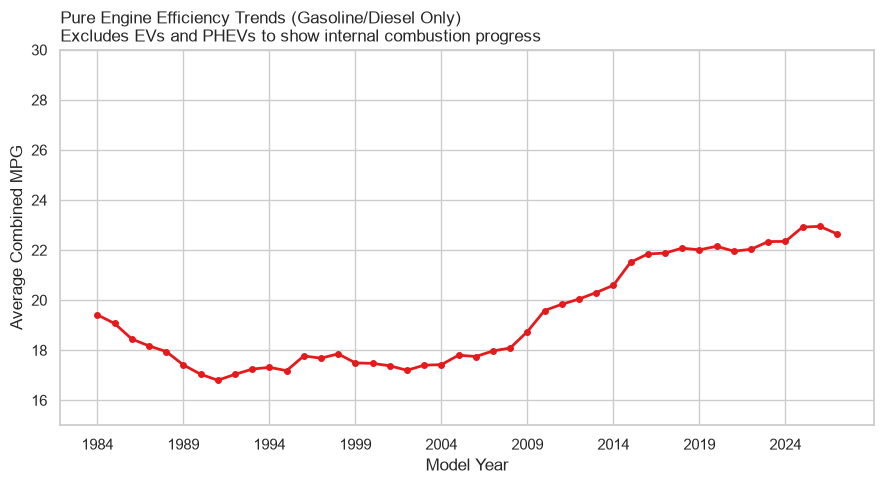

In [7]:
# Gasoline/Diesel only, to see "pure" engine improvements
avg_gasoline = (
    df[df["fuelType1"].isin(["Regular Gasoline", "Premium Gasoline", "Diesel"])]
      .groupby("year", as_index=False)
      .agg(avg_mpg_gas=("comb08", "mean"))
)

# Plot 4: Gasoline-only average combined MPG over time
fig4, ax4 = plt.subplots(figsize=(9, 5))
ax4.plot(avg_gasoline["year"], avg_gasoline["avg_mpg_gas"],
         color="#E41A1C", linewidth=2, marker="o", markersize=4)
ax4.set_xticks(np.arange(1984, 2027, 5))
ax4.set_ylim(15, 30)
ax4.set_title("Pure Engine Efficiency Trends (Gasoline/Diesel Only)\n"
              "Excludes EVs and PHEVs to show internal combustion progress",
              loc="left", fontsize=12)
ax4.set(xlabel="Model Year", ylabel="Average Combined MPG")
fig4.tight_layout()
plt.show()
